In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/MultiCausGRN_Pompe/

/content/drive/MyDrive/MultiCausGRN_Pompe


In [ ]:
!mkdir -p pompe_gse159062/{raw,processed,results,scripts,meta}

!mv Datasets/GSE159062/GSE159062_* Human.GRCh38.p13.annot.tsv.gz pompe_gse159062/raw/
%cd pompe_gse159062/raw

!gunzip -k GSE159062_raw_counts_GRCh38.p13_NCBI.tsv.gz
!gunzip -k GSE159062_norm_counts_FPKM_GRCh38.p13_NCBI.tsv.gz
!gunzip -k GSE159062_norm_counts_TPM_GRCh38.p13_NCBI.tsv.gz
!gunzip -k Human.GRCh38.p13.annot.tsv.gz
!gunzip -k GSE159062_series_matrix.txt.gz
!gunzip -k GSE159062_family.soft.gz
!gunzip -k GSE159062_Pompe_vs_healthy-expression_matrix.csv.gz
!gunzip -k GSE159062_rhGAA_vs_untreated-Pompe_expression_matrix.csv.gz

mv: cannot stat 'Datasets/GSE159062/GSE159062_*': No such file or directory
mv: cannot stat 'Human.GRCh38.p13.annot.tsv.gz': No such file or directory
/content/drive/MyDrive/MultiCausGRN_Pompe/pompe_gse159062/raw
gzip: Human.GRCh38.p13.annot.tsv.gz: No such file or directory


In [ ]:
!gunzip -k Human.GRCh38.p13.annot.tsv.gz

In [ ]:
%cd ../
import pandas as pd

counts = pd.read_csv("raw/GSE159062_raw_counts_GRCh38.p13_NCBI.tsv", sep="\t")
annot  = pd.read_csv("raw/Human.GRCh38.p13.annot.tsv", sep="\t")

print("Counts shape:", counts.shape)
print(counts.head())
print(counts.columns[:10])

print("\nAnnotation shape:", annot.shape)
print(annot.head())
print(annot.columns)

/content/drive/MyDrive/MultiCausGRN_Pompe/pompe_gse159062
Counts shape: (39376, 11)
      GeneID  GSM4818509  GSM4818510  GSM4818511  GSM4818512  GSM4818513  \
0  100287102          16          15          19          36          37   
1     653635         705         627         522         556         732   
2  102466751          10           4           2           1           5   
3  107985730           3           4           1           3           2   
4  100302278           0           0           0           1           0   

   GSM4818514  GSM4818515  GSM4818516  GSM4818517  GSM4818518  
0          11          38          33           7          34  
1         688         575         723         511         530  
2           3           3           5           3           1  
3           5           3           2           0           2  
4           0           0           0           0           0  
Index(['GeneID', 'GSM4818509', 'GSM4818510', 'GSM4818511', 'GSM4818512',
  

/tmp/ipykernel_27674/96656845.py:5: DtypeWarning: Columns (8,9) have mixed types. Specify dtype option on import or set low_memory=False.
  annot  = pd.read_csv("raw/Human.GRCh38.p13.annot.tsv", sep="\t")


In [ ]:
import pandas as pd

# Load data
counts = pd.read_csv("raw/GSE159062_raw_counts_GRCh38.p13_NCBI.tsv", sep="\t")
annot  = pd.read_csv("raw/Human.GRCh38.p13.annot.tsv", sep="\t", low_memory=False)

# Merge on GeneID
merged = counts.merge(annot, on="GeneID", how="left")

# Use Symbol as gene name
merged["gene_symbol"] = merged["Symbol"].astype(str)

# Keep only relevant columns
sample_cols = [c for c in counts.columns if c != "GeneID"]
expr = merged[["gene_symbol", "GeneType"] + sample_cols].copy()

print(expr.head())

   gene_symbol GeneType  GSM4818509  GSM4818510  GSM4818511  GSM4818512  \
0      DDX11L1   pseudo          16          15          19          36   
1       WASH7P   pseudo         705         627         522         556   
2    MIR6859-1    ncRNA          10           4           2           1   
3  MIR1302-2HG    ncRNA           3           4           1           3   
4    MIR1302-2    ncRNA           0           0           0           1   

   GSM4818513  GSM4818514  GSM4818515  GSM4818516  GSM4818517  GSM4818518  
0          37          11          38          33           7          34  
1         732         688         575         723         511         530  
2           5           3           3           5           3           1  
3           2           5           3           2           0           2  
4           0           0           0           0           0           0  


In [ ]:
# remove bad symbols
expr = expr[expr["gene_symbol"].notna()]
expr = expr[expr["gene_symbol"] != "nan"]
expr = expr[expr["gene_symbol"] != ""]

# filter gene types (very important)
expr = expr[expr["GeneType"].isin(["protein-coding", "ncRNA"])]

# OPTIONAL stricter (recommended later):
# expr = expr[expr["GeneType"] == "protein-coding"]

# drop GeneType after filtering
expr = expr.drop(columns=["GeneType"])

print("After filtering:", expr.shape)

After filtering: (34896, 11)


In [ ]:
expr = expr.groupby("gene_symbol", as_index=False)[sample_cols].sum()
print("After duplicate removal:", expr.shape)

After duplicate removal: (34896, 11)


In [ ]:
mask = (expr[sample_cols] > 0).sum(axis=1) >= 2
expr = expr.loc[mask].copy()

print("After expression filter:", expr.shape)

After expression filter: (26113, 11)


In [ ]:
expr.to_csv("processed/GSE159062_counts_clean.csv", index=False)

In [ ]:
import numpy as np

lib_sizes = expr[sample_cols].sum(axis=0)
cpm = expr[sample_cols].div(lib_sizes, axis=1) * 1e6
log_cpm = np.log2(cpm + 1)

expr_log = pd.concat([expr[["gene_symbol"]], log_cpm], axis=1)
expr_log.to_csv("processed/GSE159062_logCPM.csv", index=False)

print(expr_log.shape)

(26113, 11)


In [ ]:
print("Final genes:", expr_log.shape[0])
print("Samples:", expr_log.shape[1] - 1)

Final genes: 26113
Samples: 10


In [ ]:
print(expr_log.shape)

(26113, 11)


In [ ]:
import pandas as pd

expr = pd.read_csv("processed/GSE159062_logCPM.csv")
genes = set(expr["gene_symbol"].astype(str))

print("Total genes:", len(genes))

Total genes: 26113


Identifying the TFs

In [ ]:
expr = pd.read_csv("processed/GSE159062_logCPM.csv")
genes = set(expr["gene_symbol"].astype(str))

In [ ]:
%cd pompe_gse159062/
import pandas as pd

tf_raw = pd.read_csv("raw/all_tf_list.txt", sep="\t", low_memory=False)
print(tf_raw.shape)
print(tf_raw.columns.tolist())
print(tf_raw.head())

[Errno 2] No such file or directory: 'pompe_gse159062/'
/content/drive/MyDrive/MultiCausGRN_Pompe/pompe_gse159062
(274815, 6)
['Species', 'Symbol', 'Ensembl', 'Family', 'Protein', 'Entrez_ID']
                       Species  Symbol             Ensembl   Family  \
0  Acanthochromis_polyacanthus  klf12b  ENSAPOG00000021372  zf-C2H2   
1  Acanthochromis_polyacanthus  lin28a  ENSAPOG00000014331      CSD   
2  Acanthochromis_polyacanthus   tox4a  ENSAPOG00000015607      HMG   
3  Acanthochromis_polyacanthus  bhlha9  ENSAPOG00000014064     bHLH   
4  Acanthochromis_polyacanthus  znf346  ENSAPOG00000006793  zf-C2H2   

                                             Protein  Entrez_ID  
0  ENSAPOP00000018022.1;ENSAPOP00000033039.1;ENSA...  110951947  
1                              ENSAPOP00000011727.1;        NaN  
2                              ENSAPOP00000012871.1;  110953255  
3                              ENSAPOP00000011500.1;        NaN  
4                              ENSAPOP00000005144.

In [ ]:
tf_list = tf_raw[["Symbol"]].copy()
tf_list.columns = ["tf"]
tf_list["tf"] = tf_list["tf"].astype(str).str.strip()

print("Total TFs:", len(tf_list))
print(tf_list.head())

Total TFs: 274815
       tf
0  klf12b
1  lin28a
2   tox4a
3  bhlha9
4  znf346


In [ ]:
expr = pd.read_csv("processed/GSE159062_logCPM.csv")
genes = set(expr["gene_symbol"].astype(str).str.strip())

tf_final = tf_list[tf_list["tf"].isin(genes)].drop_duplicates().reset_index(drop=True)

tf_final.to_csv("processed/TF_final.csv", index=False)

print("TFs present in dataset:", len(tf_final))
print(tf_final.head())

TFs present in dataset: 1745
       tf
0  POU3F2
1  CSRNP3
2  DMRTA1
3    USF2
4   ZMIZ2


In [ ]:
print(tf_raw.columns.tolist())
print(tf_raw.head())

['Species', 'Symbol', 'Ensembl', 'Family', 'Protein', 'Entrez_ID']
                       Species  Symbol             Ensembl   Family  \
0  Acanthochromis_polyacanthus  klf12b  ENSAPOG00000021372  zf-C2H2   
1  Acanthochromis_polyacanthus  lin28a  ENSAPOG00000014331      CSD   
2  Acanthochromis_polyacanthus   tox4a  ENSAPOG00000015607      HMG   
3  Acanthochromis_polyacanthus  bhlha9  ENSAPOG00000014064     bHLH   
4  Acanthochromis_polyacanthus  znf346  ENSAPOG00000006793  zf-C2H2   

                                             Protein  Entrez_ID  
0  ENSAPOP00000018022.1;ENSAPOP00000033039.1;ENSA...  110951947  
1                              ENSAPOP00000011727.1;        NaN  
2                              ENSAPOP00000012871.1;  110953255  
3                              ENSAPOP00000011500.1;        NaN  
4                              ENSAPOP00000005144.1;  110965834  


In [ ]:
tf_raw = pd.read_csv("raw/all_tf_list.txt", sep="\t", low_memory=False)

# keep only human
tf_human = tf_raw[tf_raw["Species"] == "Homo_sapiens"].copy()

print("Human TFs:", len(tf_human))

Human TFs: 1659


In [ ]:
tf_list = tf_human[["Symbol"]].copy()
tf_list.columns = ["tf"]

tf_list["tf"] = tf_list["tf"].astype(str).str.strip()

print("Clean TF list:", len(tf_list))
print(tf_list.head())

Clean TF list: 1659
            tf
102579    ATF1
102580     nan
102581    SOX3
102582    SPIB
102583  ZNF620


In [ ]:
expr = pd.read_csv("processed/GSE159062_logCPM.csv")
genes = set(expr["gene_symbol"].astype(str).str.strip())

tf_final = tf_list[tf_list["tf"].isin(genes)].drop_duplicates().reset_index(drop=True)

tf_final.to_csv("processed/TF_final.csv", index=False)

print("TFs in dataset:", len(tf_final))

TFs in dataset: 1518


Getting Trust TF edges to apply for Causality

In [ ]:
import pandas as pd

trrust = pd.read_csv(
    "raw/trrust_rawdata.txt.gz",  # adjust name if needed
    sep="\t",
    header=None,
    names=["TF", "Target", "Effect", "PMID"]
)

print("Shape:", trrust.shape)
print(trrust.head())

Shape: (8215, 4)
     TF  Target      Effect      PMID
0  AATF    BAK1     Unknown  22983126
1  AATF     BAX  Repression  22909821
2  AATF    BBC3     Unknown  22983126
3  AATF  CDKN1A     Unknown  17157788
4  AATF     MYC  Activation  20549547


In [ ]:
trrust["TF"] = trrust["TF"].astype(str).str.strip()
trrust["Target"] = trrust["Target"].astype(str).str.strip()

In [ ]:
expr = pd.read_csv("processed/GSE159062_logCPM.csv")
genes = set(expr["gene_symbol"].astype(str).str.strip())

tf_final = pd.read_csv("processed/TF_final.csv")
tf_set = set(tf_final["tf"].astype(str).str.strip())

prior_edges = trrust[
    (trrust["TF"].isin(tf_set)) &
    (trrust["Target"].isin(genes))
].drop_duplicates().reset_index(drop=True)

prior_edges.to_csv("processed/prior_edges_trrust.csv", index=False)

print("Prior edges:", len(prior_edges))
print(prior_edges.head())

Prior edges: 6124
    TF Target      Effect      PMID
0  AHR  ABCG2     Unknown  20460431
1  AHR   AHRR  Activation  18848529
2  AHR   ARNT     Unknown  19255421
3  AHR  BRCA1     Unknown  18259752
4  AHR    CA9  Repression  19154183


In [ ]:
print(trrust.shape)

(8215, 4)


In [ ]:
print(len(prior_edges))

6124


Now preparing the input for MutliCasuGRN

In [ ]:
import pandas as pd

series_file = "raw/GSE159062_series_matrix.txt"

rows = {}
with open(series_file, "r", encoding="utf-8", errors="ignore") as f:
    for line in f:
        if line.startswith("!Sample_"):
            parts = line.strip().split("\t")
            key = parts[0].replace("!Sample_", "")
            vals = [x.strip('"') for x in parts[1:]]
            rows[key] = vals

meta = pd.DataFrame(rows)

print(meta.head())
print(meta.columns)

                           title geo_accession                 status  \
0                 Healthy-s110-1    GSM4818509  Public on Oct 06 2020   
1                 Healthy-s111-2    GSM4818510  Public on Oct 06 2020   
2                 Healthy-s115-3    GSM4818511  Public on Oct 06 2020   
3                 Healthy-s116-4    GSM4818512  Public on Oct 06 2020   
4  Infantile Pompe-untreated - A    GSM4818513  Public on Oct 06 2020   

  submission_date last_update_date type channel_count  \
0     Oct 05 2020      Oct 06 2020  SRA             1   
1     Oct 05 2020      Oct 06 2020  SRA             1   
2     Oct 05 2020      Oct 06 2020  SRA             1   
3     Oct 05 2020      Oct 06 2020  SRA             1   
4     Oct 05 2020      Oct 06 2020  SRA             1   

                   source_name_ch1  organism_ch1 characteristics_ch1  ...  \
0  3D engineered tissue, myobundle  Homo sapiens     treatment: none  ...   
1  3D engineered tissue, myobundle  Homo sapiens     treatment: 

In [ ]:
# combine all descriptive text
text_cols = [c for c in meta.columns if "characteristics" in c or c in ["title", "source_name_ch1"]]

meta["all_text"] = meta[text_cols].fillna("").astype(str).agg(" | ".join, axis=1).str.lower()

def assign_condition(text):
    if "rhgaa" in text or "treated" in text:
        return "Pompe_rhGAA"
    elif "pompe" in text or "iopd" in text:
        return "Pompe"
    elif "healthy" in text or "control" in text:
        return "Control"
    else:
        return "UNKNOWN"

meta["condition"] = meta["all_text"].apply(assign_condition)

print(meta[["geo_accession", "title", "condition"]])
print(meta["condition"].value_counts())

  geo_accession                              title    condition
0    GSM4818509                     Healthy-s110-1      Control
1    GSM4818510                     Healthy-s111-2      Control
2    GSM4818511                     Healthy-s115-3      Control
3    GSM4818512                     Healthy-s116-4      Control
4    GSM4818513      Infantile Pompe-untreated - A  Pompe_rhGAA
5    GSM4818514      Infantile Pompe-untreated - B  Pompe_rhGAA
6    GSM4818515      Infantile Pompe-untreated - C  Pompe_rhGAA
7    GSM4818516  Infantile Pompe-rhGAA treated - A  Pompe_rhGAA
8    GSM4818517  Infantile Pompe-rhGAA treated - B  Pompe_rhGAA
9    GSM4818518  Infantile Pompe-rhGAA treated - C  Pompe_rhGAA
condition
Pompe_rhGAA    6
Control        4
Name: count, dtype: int64


In [ ]:
import os

os.makedirs("processed", exist_ok=True)

meta.to_csv("processed/GSE159062_sample_metadata_initial.csv", index=False)

print("Metadata saved!")

Metadata saved!


In [ ]:
expr = pd.read_csv("processed/GSE159062_logCPM.csv")
meta = pd.read_csv("processed/GSE159062_sample_metadata_initial.csv")

keep = meta[meta["condition"].isin(["Control", "Pompe"])].copy()

samples_keep = keep["geo_accession"].astype(str).tolist()

cols = ["gene_symbol"] + [c for c in expr.columns if c in samples_keep]

expr_cp = expr[cols].copy()

expr_cp.to_csv("processed/control_vs_pompe_expression.csv", index=False)

print("Saved:", expr_cp.shape)

Saved: (26113, 5)


In [ ]:
print(meta["condition"].value_counts())

condition
Pompe_rhGAA    6
Control        4
Name: count, dtype: int64


In [ ]:
meta = pd.read_csv("processed/GSE159062_sample_metadata_initial.csv")

cols_to_show = [c for c in ["geo_accession", "title", "source_name_ch1", "all_text"] if c in meta.columns]
print(meta[cols_to_show].to_string(index=False))

geo_accession                             title                 source_name_ch1                                                                                                                                                                                  all_text
   GSM4818509                    Healthy-s110-1 3D engineered tissue, myobundle                                                                                                                        healthy-s110-1 | 3d engineered tissue, myobundle | treatment: none
   GSM4818510                    Healthy-s111-2 3D engineered tissue, myobundle                                                                                                                        healthy-s111-2 | 3d engineered tissue, myobundle | treatment: none
   GSM4818511                    Healthy-s115-3 3D engineered tissue, myobundle                                                                                                                        hea

In [ ]:
import pandas as pd

meta = pd.read_csv("processed/GSE159062_sample_metadata_initial.csv")

manual_map = {
    "GSM4818509": "Control",
    "GSM4818510": "Control",
    "GSM4818511": "Control",
    "GSM4818512": "Control",
    "GSM4818513": "Pompe",
    "GSM4818514": "Pompe",
    "GSM4818515": "Pompe",
    "GSM4818516": "Pompe_rhGAA",
    "GSM4818517": "Pompe_rhGAA",
    "GSM4818518": "Pompe_rhGAA",
}

meta["condition"] = meta["geo_accession"].map(manual_map)

print(meta[["geo_accession", "condition"]].to_string(index=False))
print(meta["condition"].value_counts())

meta.to_csv("processed/GSE159062_sample_metadata_initial.csv", index=False)

geo_accession   condition
   GSM4818509     Control
   GSM4818510     Control
   GSM4818511     Control
   GSM4818512     Control
   GSM4818513       Pompe
   GSM4818514       Pompe
   GSM4818515       Pompe
   GSM4818516 Pompe_rhGAA
   GSM4818517 Pompe_rhGAA
   GSM4818518 Pompe_rhGAA
condition
Control        4
Pompe          3
Pompe_rhGAA    3
Name: count, dtype: int64


In [ ]:
expr = pd.read_csv("processed/GSE159062_logCPM.csv")
meta = pd.read_csv("processed/GSE159062_sample_metadata_initial.csv")

keep = meta[meta["condition"].isin(["Control", "Pompe"])].copy()

samples_keep = keep["geo_accession"].astype(str).tolist()

cols = ["gene_symbol"] + [c for c in expr.columns if c in samples_keep]

expr_cp = expr[cols].copy()

expr_cp.to_csv("processed/control_vs_pompe_expression.csv", index=False)
keep.to_csv("processed/control_vs_pompe_metadata.csv", index=False)

print("Expression shape:", expr_cp.shape)
print(keep[["geo_accession", "condition"]].to_string(index=False))

Expression shape: (26113, 8)
geo_accession condition
   GSM4818509   Control
   GSM4818510   Control
   GSM4818511   Control
   GSM4818512   Control
   GSM4818513     Pompe
   GSM4818514     Pompe
   GSM4818515     Pompe


In [ ]:
%cd pompe_gse159062/

/content/drive/MyDrive/MultiCausGRN_Pompe/pompe_gse159062


In [ ]:
import pandas as pd

expr = pd.read_csv("processed/control_vs_pompe_expression.csv")
sample_cols = expr.columns[1:]

# compute variance
expr["variance"] = expr[sample_cols].var(axis=1)

# select top 5000
expr_top5000 = expr.sort_values("variance", ascending=False).head(5000).copy()

top_genes = set(expr_top5000["gene_symbol"].astype(str))

print("Top genes:", len(top_genes))

Top genes: 5000


In [ ]:
pompe_core = set([
    "GAA",        # disease gene
    "TFEB",       # lysosome master regulator
    "LAMP2",      # lysosomal membrane
    "BECN1",      # autophagy
    "SQSTM1",     # autophagy cargo
    "MTOR",       # regulation axis
    "PPARGC1A"    # metabolism / mitochondria
])

print("Pompe core:", len(pompe_core))

Pompe core: 7


In [ ]:
tf_final = pd.read_csv("processed/TF_final.csv")
tf_genes = set(tf_final["tf"].astype(str))

print("TF genes:", len(tf_genes))

TF genes: 1518


In [ ]:
final_genes = top_genes.union(tf_genes).union(pompe_core)

print("Final genes:", len(final_genes))

Final genes: 6116


In [ ]:
expr_final = expr[expr["gene_symbol"].isin(final_genes)].copy()

expr_final = expr_final.drop(columns=["variance"])

expr_final.to_csv("processed/control_vs_pompe_FINAL.csv", index=False)

print(expr_final.shape)

(6116, 8)


In [ ]:
tfs = list(tf_genes)
targets = list(final_genes)

tf_df = pd.DataFrame({"TF": tfs})
target_df = pd.DataFrame({"Target": targets})

candidate_edges = tf_df.merge(target_df, how="cross")

candidate_edges = candidate_edges[candidate_edges["TF"] != candidate_edges["Target"]]

candidate_edges.to_csv("processed/candidate_edges_FINAL.csv", index=False)

print("Candidate edges:", candidate_edges.shape)

Candidate edges: (9282570, 2)


In [ ]:
prior_edges = pd.read_csv("processed/prior_edges_trrust.csv")

final_gene_set = set(final_genes)

prior_final = prior_edges[
    (prior_edges["TF"].isin(tf_genes)) &
    (prior_edges["Target"].isin(final_gene_set))
]

prior_final.to_csv("processed/prior_edges_FINAL.csv", index=False)

print("Final prior edges:", len(prior_final))

Final prior edges: 3176


In [ ]:
import os
import pandas as pd
import numpy as np

os.makedirs("pompe_model_input", exist_ok=True)

# 1) Load final expression matrix
expr = pd.read_csv("processed/control_vs_pompe_FINAL.csv")

# Expect first column = gene_symbol, remaining columns = samples
gene_col = "gene_symbol"
sample_cols = [c for c in expr.columns if c != gene_col]

# 2) Build gene index map
genes = expr[gene_col].astype(str).tolist()
gene_to_idx = {g: i for i, g in enumerate(genes)}

gene_index_map = pd.DataFrame({
    "gene_symbol": genes,
    "index": list(range(len(genes)))
})
gene_index_map.to_csv("pompe_model_input/gene_index_map.csv", index=False)

# 3) Save expression in GENELink-style format: genes as index
expr_model = expr.set_index(gene_col)
expr_model.to_csv("pompe_model_input/ExpressionData_clean.csv")

print("Expression shape:", expr_model.shape)
print("Number of genes:", len(genes))
print("Number of samples:", len(sample_cols))

Expression shape: (6116, 7)
Number of genes: 6116
Number of samples: 7


In [ ]:
# 4) TF.csv
tf_final = pd.read_csv("processed/TF_final.csv")
tf_symbols = tf_final["tf"].astype(str).tolist()
tf_indices = sorted({gene_to_idx[g] for g in tf_symbols if g in gene_to_idx})

tf_df = pd.DataFrame({"index": tf_indices})
tf_df.to_csv("pompe_model_input/TF.csv", index=False)

# 5) Target.csv = all genes in final expression set
target_df = pd.DataFrame({"index": list(range(len(genes)))})
target_df.to_csv("pompe_model_input/Target.csv", index=False)

print("TF count in final matrix:", len(tf_indices))
print("Target count:", len(genes))

TF count in final matrix: 1518
Target count: 6116


In [ ]:
# 6) Prior edges -> indexed Positive_edges.csv
prior = pd.read_csv("processed/prior_edges_FINAL.csv")

prior = prior[
    prior["TF"].isin(gene_to_idx) &
    prior["Target"].isin(gene_to_idx)
].copy()

prior["tf_idx"] = prior["TF"].map(gene_to_idx)
prior["target_idx"] = prior["Target"].map(gene_to_idx)

prior_idx = prior[["tf_idx", "target_idx"]].drop_duplicates().copy()
prior_idx.to_csv("pompe_model_input/Positive_edges.csv", index=False)

print("Indexed prior edges:", len(prior_idx))
print(prior_idx.head())

Indexed prior edges: 3091
   tf_idx  target_idx
0     143          12
1     143         144
2     143         313
3     143         567
4     143         678


In [ ]:
import pandas as pd
import numpy as np
import os

os.makedirs("pompe_model_input", exist_ok=True)

seed = 8
rng = np.random.default_rng(seed)

pos = pd.read_csv("pompe_model_input/Positive_edges.csv").drop_duplicates().reset_index(drop=True)

# shuffle
perm = rng.permutation(len(pos))
pos = pos.iloc[perm].reset_index(drop=True)

n = len(pos)
n_train = int(0.7 * n)
n_val = int(0.15 * n)
n_test = n - n_train - n_val

pos_train = pos.iloc[:n_train].copy()
pos_val = pos.iloc[n_train:n_train+n_val].copy()
pos_test = pos.iloc[n_train+n_val:].copy()

print("Positive edges total:", n)
print("Train:", len(pos_train), "Val:", len(pos_val), "Test:", len(pos_test))

# save train prior ONLY for adjacency construction
pos_train.to_csv("pompe_model_input/Prior_train_edges.csv", index=False)

Positive edges total: 3091
Train: 2163 Val: 463 Test: 465


In [ ]:
import pandas as pd
import numpy as np

tf_df = pd.read_csv("pompe_model_input/TF.csv")
target_df = pd.read_csv("pompe_model_input/Target.csv")
pos = pd.read_csv("pompe_model_input/Positive_edges.csv").drop_duplicates()

tf_indices = tf_df["index"].astype(int).tolist()
target_indices = target_df["index"].astype(int).tolist()

positive_set = set(zip(pos["tf_idx"].astype(int), pos["target_idx"].astype(int)))

# also avoid self loops
all_possible = [(tf, tg) for tf in tf_indices for tg in target_indices if tf != tg]
print("All possible TF-target pairs:", len(all_possible))

negative_pool = [(tf, tg) for (tf, tg) in all_possible if (tf, tg) not in positive_set]
print("Available negatives:", len(negative_pool))

All possible TF-target pairs: 9282570
Available negatives: 9279502


In [ ]:
import pandas as pd
import numpy as np

tf_df = pd.read_csv("pompe_model_input/TF.csv")
target_df = pd.read_csv("pompe_model_input/Target.csv")
pos = pd.read_csv("pompe_model_input/Positive_edges.csv").drop_duplicates()

tf_indices = tf_df["index"].astype(int).to_numpy()
target_indices = target_df["index"].astype(int).to_numpy()

positive_set = set(zip(pos["tf_idx"].astype(int), pos["target_idx"].astype(int)))

def sample_negatives(n_needed, seed=8, positive_set=None, tf_indices=None, target_indices=None):
    rng = np.random.default_rng(seed)
    negs = set()
    tries = 0
    max_tries = n_needed * 50

    while len(negs) < n_needed and tries < max_tries:
        tf = int(rng.choice(tf_indices))
        tg = int(rng.choice(target_indices))
        if tf == tg:
            tries += 1
            continue
        pair = (tf, tg)
        if pair in positive_set or pair in negs:
            tries += 1
            continue
        negs.add(pair)
        tries += 1

    if len(negs) < n_needed:
        raise RuntimeError(f"Could only sample {len(negs)} negatives out of {n_needed}")
    return pd.DataFrame(list(negs), columns=["tf_idx", "target_idx"])

n_pos_total = len(pos)
neg_all = sample_negatives(
    n_needed=n_pos_total,
    seed=8,
    positive_set=positive_set,
    tf_indices=tf_indices,
    target_indices=target_indices
)

print("Sampled negatives:", len(neg_all))
print(neg_all.head())

Sampled negatives: 3091
   tf_idx  target_idx
0    3186        2304
1    5852        3749
2    4166        3752
3    3127        1580
4    3452        5312


In [ ]:
import numpy as np

rng = np.random.default_rng(8)
perm = rng.permutation(len(neg_all))
neg_all = neg_all.iloc[perm].reset_index(drop=True)

neg_train = neg_all.iloc[:len(pos_train)].copy()
neg_val = neg_all.iloc[len(pos_train):len(pos_train)+len(pos_val)].copy()
neg_test = neg_all.iloc[len(pos_train)+len(pos_val):len(pos_train)+len(pos_val)+len(pos_test)].copy()

print("Neg train:", len(neg_train), "Neg val:", len(neg_val), "Neg test:", len(neg_test))

Neg train: 2163 Neg val: 463 Neg test: 465


In [ ]:
def make_split(pos_df, neg_df):
    pos_l = pos_df.copy()
    pos_l["label"] = 1

    neg_l = neg_df.copy()
    neg_l["label"] = 0

    out = pd.concat([pos_l, neg_l], axis=0).sample(frac=1, random_state=8).reset_index(drop=True)
    return out[["tf_idx", "target_idx", "label"]]

train_set = make_split(pos_train, neg_train)
val_set = make_split(pos_val, neg_val)
test_set = make_split(pos_test, neg_test)

train_set.to_csv("pompe_model_input/Train_set2.csv", index=False)
val_set.to_csv("pompe_model_input/Validation_set2.csv", index=False)
test_set.to_csv("pompe_model_input/Test_set2.csv", index=False)

print("Train set:", train_set.shape, "Pos rate:", train_set["label"].mean())
print("Val set:", val_set.shape, "Pos rate:", val_set["label"].mean())
print("Test set:", test_set.shape, "Pos rate:", test_set["label"].mean())

Train set: (4326, 3) Pos rate: 0.5
Val set: (926, 3) Pos rate: 0.5
Test set: (930, 3) Pos rate: 0.5


In [ ]:
!python /content/drive/MyDrive/MultiCausGRN_Pompe/MultiCausGRN/Code/main_Pompe.py --prior_edges /content/drive/MyDrive/MultiCausGRN_Pompe/pompe_gse159062/pompe_model_input/Prior_train_edges.csv

train row: [1585  450    1] int64 int64
train pos rate: 0.5
val pos rate: 0.5
test pos rate: 0.5
Prior edges loaded: 2163 from /content/drive/MyDrive/MultiCausGRN_Pompe/pompe_gse159062/pompe_model_input/Prior_train_edges.csv
Prior idx max: 6095 n_genes: 6116
/content/drive/MyDrive/MultiCausGRN_Pompe/MultiCausGRN/Code/utils.py:95: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  i = torch.LongTensor([coo.row, coo.col])
Epoch:1 train_loss:10.1674 val_AUC:0.8869 val_AUPR:0.8843
[best so far] epoch=1 val_AUPR=0.8843
Epoch:2 train_loss:8.8837 val_AUC:0.8915 val_AUPR:0.8794
[best so far] epoch=1 val_AUPR=0.8843
Epoch:3 train_loss:8.5737 val_AUC:0.8994 val_AUPR:0.9022
[best so far] epoch=3 val_AUPR=0.9022
Epoch:4 train_loss:7.6024 val_AUC:0.8974 val_AUPR:0.8986
[best so far] epoc

Resutls Interpretation after running on HPC

In [ ]:
!ls

Datasets  MultiCausGRN	MultiCausGRN_Pompe.ipynb  pompe_gse159062  Results


In [ ]:
import pandas as pd

hub = pd.read_csv("Results/Pompe/POMPE_GSE159062_genes6116_seed8/test_final_hub_tfs.csv")
top10 = hub.sort_values("score_sum", ascending=False).head(10)
print(top10)

   index     TF  score_sum  score_mean  n_edges
0    328    SP1  35.305700    0.980714       36
1    225  NFKB1  17.821787    0.937989       19
2    290   RELA  17.477617    0.970979       18
3    381   TP53  16.331990    0.960705       17
4     56   E2F1  14.538235    0.969216       15
5    331    SP3  12.519550    0.963042       13
6    345  STAT3   7.819183    0.977398        8
7    208    MYC   7.815543    0.976943        8
8     69   ESR1   7.549415    0.943677        8
9     36  CREB1   6.832149    0.976021        7


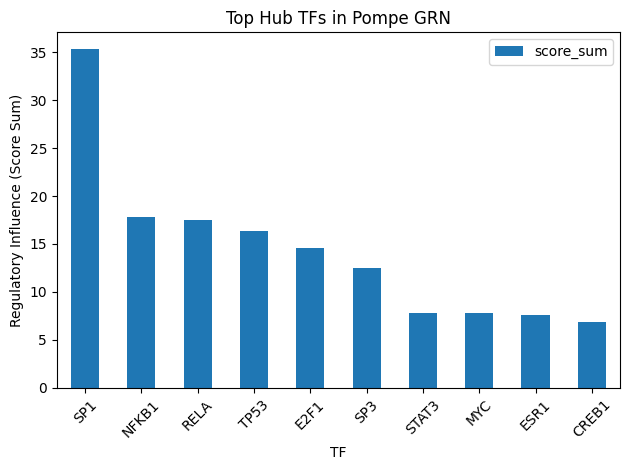

In [ ]:
import matplotlib.pyplot as plt

top10.plot.bar(x='TF', y='score_sum')
plt.title("Top Hub TFs in Pompe GRN")
plt.ylabel("Regulatory Influence (Score Sum)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
edges = pd.read_csv("Results/Pompe/POMPE_GSE159062_genes6116_seed8/test_final_predictions_named.csv")
top_edges = edges.sort_values("score", ascending=False).head(30)
print(top_edges)

     tf_idx  target_idx  label     score      TF  Target
458    1269        1274      1  0.999061    E2F1    E2F6
358    4765        3222      1  0.998930     SP1    MYCN
492    4765         628      1  0.998836     SP1    CBFB
564    1269        3214      1  0.998818    E2F1     MYB
800    4186        5228      1  0.998753    RELA    TP53
817    4765        1997      1  0.998573     SP1   HNF4A
224    4765        3771      1  0.998545     SP1     PGR
536    4772        3222      1  0.998541     SP3    MYCN
558    1269         263      1  0.998512    E2F1      AR
46     4765        1269      1  0.998492     SP1    E2F1
582    4867        1130      1  0.998449   STAT3   DDIT3
908     985        2274      1  0.998393   CREB1     JUN
338    5228        5228      1  0.998369    TP53    TP53
762    5228        5233      1  0.998340    TP53    TP73
274    4765        3383      1  0.998301     SP1   NFKB1
779    1413        1395      1  0.998243    ETS1     ERG
52     4765        2107      1 

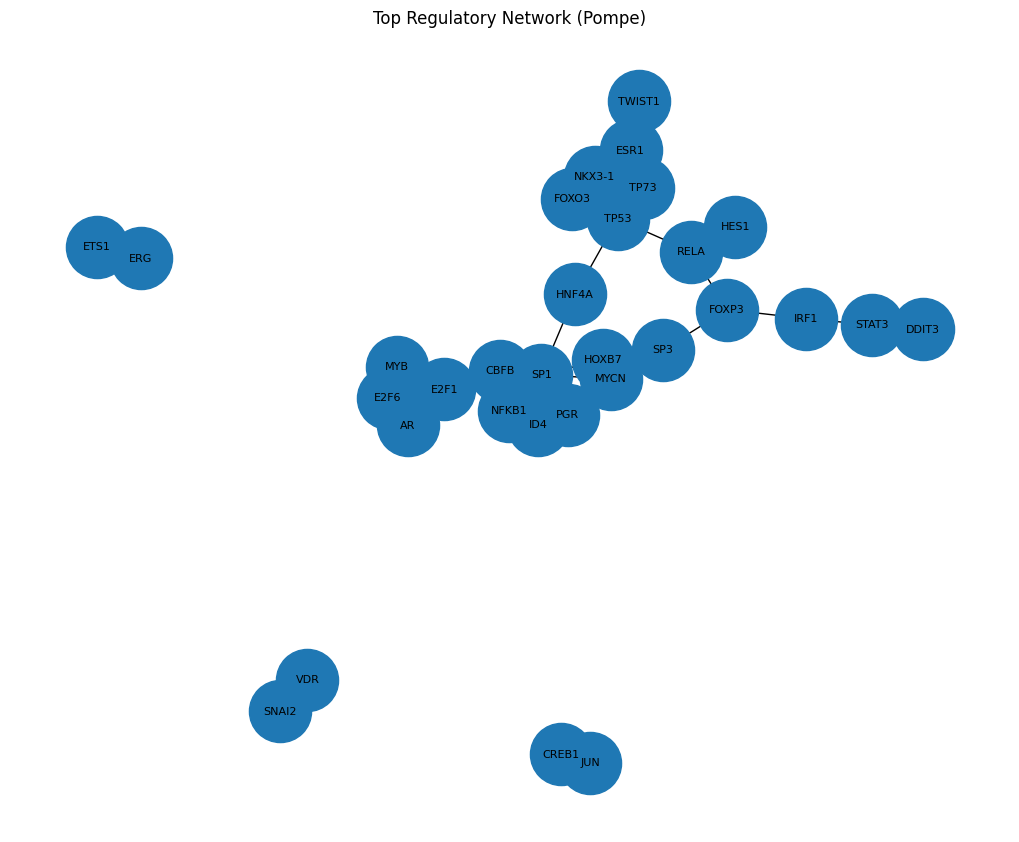

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.from_pandas_edgelist(top_edges, 'TF', 'Target')

plt.figure(figsize=(10,8))
nx.draw(G, with_labels=True, node_size=2000, font_size=8)
plt.title("Top Regulatory Network (Pompe)")
plt.show()

checking the new edges (novelty)

In [ ]:
import pandas as pd

pred = pd.read_csv("Results/Pompe/POMPE_GSE159062_genes6116_seed8/test_final_predictions_named.csv")

In [ ]:
trust = pd.read_csv("pompe_gse159062/raw/trrust_rawdata.txt.gz", sep="\t", header=None)
trust.columns = ["TF", "Target", "Effect", "PMID"]

In [ ]:
pred["TF"] = pred["TF"].str.upper()
pred["Target"] = pred["Target"].str.upper()

trust["TF"] = trust["TF"].str.upper()
trust["Target"] = trust["Target"].str.upper()

In [ ]:
pred["edge"] = pred["TF"] + "_" + pred["Target"]
trust["edge"] = trust["TF"] + "_" + trust["Target"]

trust_set = set(trust["edge"])

In [ ]:
pred["in_trrust"] = pred["edge"].isin(trust_set)

In [ ]:
total = len(pred)
known = pred["in_trrust"].sum()
novel = total - known

print(f"Total edges: {total}")
print(f"Known (TRRUST): {known} ({known/total:.2%})")
print(f"Novel: {novel} ({novel/total:.2%})")

Total edges: 930
Known (TRRUST): 465 (50.00%)
Novel: 465 (50.00%)


In [ ]:
top = pred.sort_values("score", ascending=False).head(100)

In [ ]:
top_known = top["in_trrust"].sum()
top_novel = len(top) - top_known

print(f"Top100 known: {top_known}")
print(f"Top100 novel: {top_novel}")

Top100 known: 97
Top100 novel: 3


In [ ]:
novel_edges = pred[~pred["in_trrust"]]

novel_by_tf = novel_edges.groupby("TF").size().sort_values(ascending=False)
print(novel_by_tf.head(10))

TF
ZNF142    4
GLIS3     3
ZNF419    3
GZF1      3
KLF16     3
HOXA6     3
BCL11B    2
ZNF717    2
ARID1A    2
ZNF526    2
dtype: int64


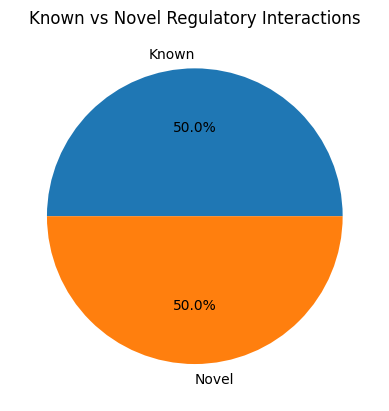

In [ ]:
import matplotlib.pyplot as plt

labels = ['Known', 'Novel']
sizes = [465, 465]

plt.pie(sizes, labels=labels, autopct='%1.1f%%')
plt.title("Known vs Novel Regulatory Interactions")
plt.show()

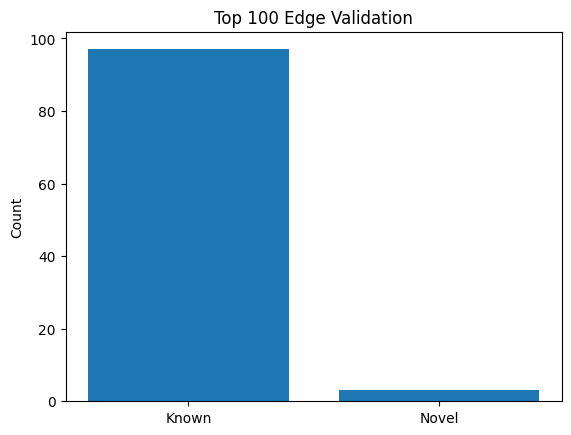

In [ ]:
labels = ['Known', 'Novel']
sizes = [97, 3]

plt.bar(labels, sizes)
plt.title("Top 100 Edge Validation")
plt.ylabel("Count")
plt.show()

Generating the supplementary files, all the TFS and new edges.

In [ ]:
import pandas as pd

# Load predictions
pred = pd.read_csv("Results/Pompe/POMPE_GSE159062_genes6116_seed8/test_final_predictions_named.csv")

# Load TRRUST
trust = pd.read_csv("pompe_gse159062/raw/trrust_rawdata.txt.gz", sep="\t", header=None)
trust.columns = ["TF", "Target", "Effect", "PMID"]

# Normalize
pred["TF"] = pred["TF"].str.upper()
pred["Target"] = pred["Target"].str.upper()
trust["TF"] = trust["TF"].str.upper()
trust["Target"] = trust["Target"].str.upper()

# Create edge IDs
pred["edge"] = pred["TF"] + "_" + pred["Target"]
trust["edge"] = trust["TF"] + "_" + trust["Target"]

trust_set = set(trust["edge"])

# Label edges
pred["in_trrust"] = pred["edge"].isin(trust_set)

# Save all
pred.to_csv("Results/Supp_Files/supp_edges_all.csv", index=False)

# Known / Novel
pred[pred["in_trrust"]].to_csv("Results/Supp_Files/supp_known_edges.csv", index=False)
pred[~pred["in_trrust"]].to_csv("Results/Supp_Files/supp_novel_edges.csv", index=False)

# Top edges
pred.sort_values("score", ascending=False).head(100).to_csv("Results/Supp_Files/supp_top100_edges.csv", index=False)

# TF ranking
hub = pd.read_csv("Results/Pompe/POMPE_GSE159062_genes6116_seed8/test_final_hub_tfs.csv")
hub.to_csv("Results/Supp_Files/supp_all_tfs.csv", index=False)

Run Pompe Vs treated to check therapy effects

In [ ]:
import pandas as pd

expr = pd.read_csv("pompe_gse159062/processed/GSE159062_logCPM.csv", index_col=0)
meta = pd.read_csv("pompe_gse159062/processed/GSE159062_sample_metadata_initial.csv")

# keep only Pompe + treated
keep = meta[meta["condition"].isin(["Pompe", "Pompe_rhGAA"])]

samples = keep["geo_accession"].values

expr_sub = expr[samples]

print(expr_sub.shape)

(26113, 6)


In [ ]:
meta_sub = meta[meta["condition"].isin(["Pompe", "Pompe_rhGAA"])].copy()

meta_sub["label"] = meta_sub["condition"].map({
    "Pompe": 1,
    "Pompe_rhGAA": 0
})

In [ ]:
genes = pd.read_csv("pompe_gse159062/pompe_model_input/gene_index_map.csv")
gene_list = genes["gene_symbol"]

expr_sub = expr_sub.loc[gene_list]

In [ ]:
expr_sub.to_csv("pompe_gse159062/processed/Pompe_VS_Treated/ExpressionData_clean.csv")

In [ ]:
%ls

meta/   pompe_model_input/  raw/     results/
model/  processed/          Result/  scripts/


In [ ]:
import pandas as pd

# full processed expression
expr_full = pd.read_csv("processed/GSE159062_logCPM.csv")

# metadata with corrected labels
meta = pd.read_csv("processed/GSE159062_sample_metadata_initial.csv")

# same genes as first experiment
gene_map = pd.read_csv("pompe_model_input/gene_index_map.csv")
gene_list = gene_map["gene_symbol"].astype(str).tolist()

# keep only Pompe + treated
meta_pt = meta[meta["condition"].isin(["Pompe", "Pompe_rhGAA"])].copy()
samples_pt = meta_pt["geo_accession"].astype(str).tolist()

# subset expression
cols = ["gene_symbol"] + [c for c in expr_full.columns if c in samples_pt]
expr_pt = expr_full[cols].copy()

# keep same genes and same order
expr_pt = expr_pt[expr_pt["gene_symbol"].isin(gene_list)].copy()
expr_pt["gene_symbol"] = pd.Categorical(expr_pt["gene_symbol"], categories=gene_list, ordered=True)
expr_pt = expr_pt.sort_values("gene_symbol").reset_index(drop=True)

# save model expression
expr_pt_model = expr_pt.set_index("gene_symbol")
expr_pt_model.to_csv("processed/Pompe_VS_Treated/ExpressionData_clean.csv")

print(expr_pt_model.shape)
print(meta_pt[["geo_accession", "condition"]])

(6116, 6)
  geo_accession    condition
4    GSM4818513        Pompe
5    GSM4818514        Pompe
6    GSM4818515        Pompe
7    GSM4818516  Pompe_rhGAA
8    GSM4818517  Pompe_rhGAA
9    GSM4818518  Pompe_rhGAA


In [ ]:
import shutil

shutil.copy("pompe_model_input/TF.csv", "processed/Pompe_VS_Treated/TF.csv")
shutil.copy("pompe_model_input/Target.csv", "processed/Pompe_VS_Treated/Target.csv")
shutil.copy("pompe_model_input/gene_index_map.csv", "processed/Pompe_VS_Treated/gene_index_map.csv")

'processed/Pompe_VS_Treated//gene_index_map.csv'

In [ ]:
prior = pd.read_csv("processed/prior_edges_FINAL.csv")
gene_to_idx = dict(zip(gene_map["gene_symbol"], gene_map["index"]))

prior = prior[
    prior["TF"].isin(gene_to_idx) &
    prior["Target"].isin(gene_to_idx)
].copy()

prior["tf_idx"] = prior["TF"].map(gene_to_idx)
prior["target_idx"] = prior["Target"].map(gene_to_idx)

prior_idx = prior[["tf_idx", "target_idx"]].drop_duplicates().copy()
prior_idx.to_csv("processed/Pompe_VS_Treated/Positive_edges.csv", index=False)

print("Prior edges:", len(prior_idx))

Prior edges: 3091


In [ ]:
import numpy as np

seed = 8
rng = np.random.default_rng(seed)

pos = pd.read_csv("processed/Pompe_VS_Treated/Positive_edges.csv").drop_duplicates().reset_index(drop=True)

perm = rng.permutation(len(pos))
pos = pos.iloc[perm].reset_index(drop=True)

n = len(pos)
n_train = int(0.7 * n)
n_val = int(0.15 * n)
n_test = n - n_train - n_val

pos_train = pos.iloc[:n_train].copy()
pos_val = pos.iloc[n_train:n_train+n_val].copy()
pos_test = pos.iloc[n_train+n_val:].copy()

pos_train.to_csv("processed/Pompe_VS_Treated/Prior_train_edges.csv", index=False)

print("Positive edges total:", n)
print("Train:", len(pos_train), "Val:", len(pos_val), "Test:", len(pos_test))

Positive edges total: 3091
Train: 2163 Val: 463 Test: 465


In [ ]:
tf_df = pd.read_csv("processed/Pompe_VS_Treated/TF.csv")
target_df = pd.read_csv("processed/Pompe_VS_Treated/Target.csv")
pos_all = pd.read_csv("processed/Pompe_VS_Treated/Positive_edges.csv").drop_duplicates()

tf_indices = tf_df["index"].astype(int).to_numpy()
target_indices = target_df["index"].astype(int).to_numpy()
positive_set = set(zip(pos_all["tf_idx"].astype(int), pos_all["target_idx"].astype(int)))

def sample_negatives(n_needed, seed=8):
    rng = np.random.default_rng(seed)
    negs = set()
    tries = 0
    max_tries = n_needed * 100

    while len(negs) < n_needed and tries < max_tries:
        tf = int(rng.choice(tf_indices))
        tg = int(rng.choice(target_indices))
        if tf == tg:
            tries += 1
            continue
        pair = (tf, tg)
        if pair in positive_set or pair in negs:
            tries += 1
            continue
        negs.add(pair)
        tries += 1

    if len(negs) < n_needed:
        raise RuntimeError(f"Could only sample {len(negs)} negatives out of {n_needed}")
    return pd.DataFrame(list(negs), columns=["tf_idx", "target_idx"])

neg_all = sample_negatives(len(pos_all), seed=8)
print("Sampled negatives:", len(neg_all))

Sampled negatives: 3091


In [ ]:
perm = rng.permutation(len(neg_all))
neg_all = neg_all.iloc[perm].reset_index(drop=True)

neg_train = neg_all.iloc[:len(pos_train)].copy()
neg_val = neg_all.iloc[len(pos_train):len(pos_train)+len(pos_val)].copy()
neg_test = neg_all.iloc[len(pos_train)+len(pos_val):len(pos_train)+len(pos_val)+len(pos_test)].copy()

print("Neg train:", len(neg_train), "Neg val:", len(neg_val), "Neg test:", len(neg_test))
def make_split(pos_df, neg_df):
    pos_l = pos_df.copy()
    pos_l["label"] = 1

    neg_l = neg_df.copy()
    neg_l["label"] = 0

    out = pd.concat([pos_l, neg_l], axis=0).sample(frac=1, random_state=8).reset_index(drop=True)
    return out[["tf_idx", "target_idx", "label"]]

train_set = make_split(pos_train, neg_train)
val_set = make_split(pos_val, neg_val)
test_set = make_split(pos_test, neg_test)

train_set.to_csv("processed/Pompe_VS_Treated/Train_set2.csv", index=False)
val_set.to_csv("processed/Pompe_VS_Treated/Validation_set2.csv", index=False)
test_set.to_csv("processed/Pompe_VS_Treated/Test_set2.csv", index=False)

print("Train set:", train_set.shape, "Pos rate:", train_set["label"].mean())
print("Val set:", val_set.shape, "Pos rate:", val_set["label"].mean())
print("Test set:", test_set.shape, "Pos rate:", test_set["label"].mean())

Neg train: 2163 Neg val: 463 Neg test: 465
Train set: (4326, 3) Pos rate: 0.5
Val set: (926, 3) Pos rate: 0.5
Test set: (930, 3) Pos rate: 0.5


In [ ]:
import pandas as pd

hub_pompe = pd.read_csv("Results/Pompe/POMPE_GSE159062_genes6116_seed8/test_final_hub_tfs.csv")
hub_treated = pd.read_csv("Results/Pompe_vs_Treated/POMPE_GSE159062_genes6116_seed8/test_final_hub_tfs.csv")

In [ ]:
hub_pompe = hub_pompe[["TF", "score_sum"]].rename(columns={"score_sum": "pompe_score"})
hub_treated = hub_treated[["TF", "score_sum"]].rename(columns={"score_sum": "treated_score"})

merged = pd.merge(hub_pompe, hub_treated, on="TF", how="outer").fillna(0)

In [ ]:
merged["change"] = merged["treated_score"] - merged["pompe_score"]

In [ ]:
down = merged.sort_values("change").head(10)
print(down)

        TF  pompe_score  treated_score    change
158   GZF1     2.401814       0.000000 -2.401814
77    E2F3     4.429874       2.319928 -2.109945
455   TAL1     2.370554       0.582926 -1.787628
436    SP4     2.487261       0.874215 -1.613046
307   NFYA     2.476430       0.992595 -1.483835
435    SP3    12.519550      11.065148 -1.454402
481  TFDP1     3.065706       1.716452 -1.349254
282    MYC     7.815543       6.579921 -1.235622
234   KLF4     3.643789       2.430144 -1.213645
451  STAT3     7.819183       6.718023 -1.101160


In [ ]:
up = merged.sort_values("change", ascending=False).head(10)
print(up)

        TF  pompe_score  treated_score    change
391  RUNX1     2.787067       4.754327  1.967261
392  RUNX3     3.658231       5.576236  1.918005
186  HOXA5     0.000000       1.634476  1.634476
253    MAF     0.000000       1.505321  1.505321
328  NR4A1     0.000000       1.461891  1.461891
20    ATF3     1.250924       2.685020  1.434096
21    ATF4     2.777992       3.959642  1.181650
499   TP73     0.726875       1.685134  0.958259
416  SMAD7     0.620221       1.571799  0.951578
338   OTX2     0.000000       0.945481  0.945481


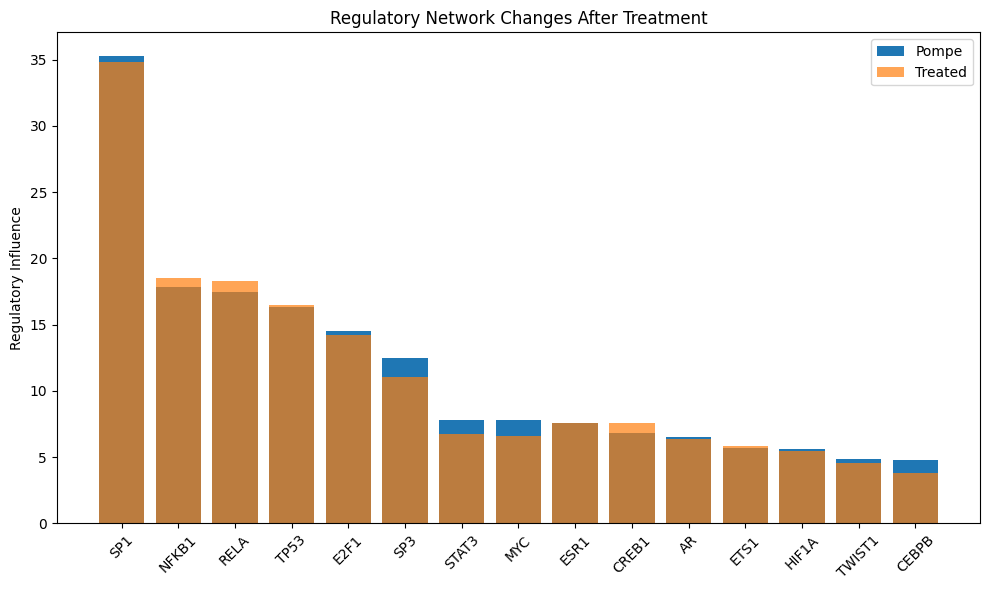

In [ ]:
import matplotlib.pyplot as plt

top = merged.sort_values("pompe_score", ascending=False).head(15)

plt.figure(figsize=(10,6))
plt.bar(top["TF"], top["pompe_score"], label="Pompe")
plt.bar(top["TF"], top["treated_score"], alpha=0.7, label="Treated")
plt.xticks(rotation=45)
plt.legend()
plt.title("Regulatory Network Changes After Treatment")
plt.ylabel("Regulatory Influence")
plt.tight_layout()
plt.show()

Validation Biologist

In [ ]:
import pandas as pd

pred = pd.read_csv("Results/Pompe/POMPE_GSE159062_genes6116_seed8/test_final_predictions_named.csv")
trust = pd.read_csv("pompe_gse159062/raw/trrust_rawdata.txt.gz", sep="\t", header=None)
trust.columns = ["TF", "Target", "Effect", "PMID"]

pred["TF"] = pred["TF"].str.upper()
pred["Target"] = pred["Target"].str.upper()
trust["TF"] = trust["TF"].str.upper()
trust["Target"] = trust["Target"].str.upper()

pred["edge"] = pred["TF"] + "_" + pred["Target"]
trust["edge"] = trust["TF"] + "_" + trust["Target"]

trust_set = set(trust["edge"])
pred["in_trrust"] = pred["edge"].isin(trust_set)

top100 = pred.sort_values("score", ascending=False).head(300)
novel_top100 = top100[~top100["in_trrust"]][["TF", "Target", "score"]]

print(novel_top100)

        TF   Target     score
531  PPARD     TP53  0.995613
539   SOX2    NHLH2  0.994794
183   KLF4     HES6  0.994775
895  STAT3    RASD2  0.962847
490   GZF1    HMGB1  0.958636
298   JUND     RGS4  0.956348
820    SP3    PAQR6  0.952488
912  CEBPB   TTTY16  0.929962
310   E2F4    PAMR1  0.916028
459  PPARA  XPNPEP2  0.909470
312   GZF1     RAG1  0.889903
102  RUNX3    ZNF35  0.887722


processing GSE386680 dataset.

In [ ]:
%cd /content/drive/MyDrive/MultiCausGRN_Pompe/

/content/drive/MyDrive/MultiCausGRN_Pompe


In [ ]:
import os
from pathlib import Path
import pandas as pd

# CHANGE THIS
folder = r"GSE38680_RAW"

folder_path = Path(folder)

# collect all files recursively
all_files = []

for root, dirs, files in os.walk(folder_path):
    for f in files:
        full_path = Path(root) / f

        all_files.append({
            "filename": f,
            "extension": full_path.suffix,
            "size_mb": round(full_path.stat().st_size / (1024*1024), 3),
            "full_path": str(full_path)
        })

df = pd.DataFrame(all_files)

# sort nicely
df = df.sort_values(["extension", "filename"])

# show all files
pd.set_option("display.max_rows", None)
print(df)

# optional save
df.to_csv("GSE38680_file_contents.csv", index=False)

print("\nTotal files:", len(df))

                     filename extension  size_mb  \
2   GSM947461_H0013501.CEL.gz       .gz    7.648   
3   GSM947462_H0013502.CEL.gz       .gz    7.628   
4   GSM947463_H0013504.CEL.gz       .gz    7.656   
5   GSM947464_H0013505.CEL.gz       .gz    7.667   
6   GSM947465_H0013506.CEL.gz       .gz    7.749   
7   GSM947466_H0013507.CEL.gz       .gz    7.705   
8   GSM947467_H0013508.CEL.gz       .gz    7.545   
9   GSM947468_H0013509.CEL.gz       .gz    7.592   
10  GSM947469_H0013510.CEL.gz       .gz    7.520   
11  GSM947470_H0013503.CEL.gz       .gz    7.730   
1   GSM947471_H0013492.CEL.gz       .gz    7.656   
0   GSM947472_H0013493.CEL.gz       .gz    7.678   
12  GSM947473_H0013494.CEL.gz       .gz    7.687   
13  GSM947474_H0013495.CEL.gz       .gz    7.688   
17  GSM947475_H0013496.CEL.gz       .gz    7.788   
16  GSM947476_H0013497.CEL.gz       .gz    7.660   
15  GSM947477_H0013498.CEL.gz       .gz    7.681   
14  GSM947478_H0013499.CEL.gz       .gz    7.692   
22  GSM94747

In [ ]:
!apt-get -qq update
!apt-get -qq install -y r-base r-base-dev

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


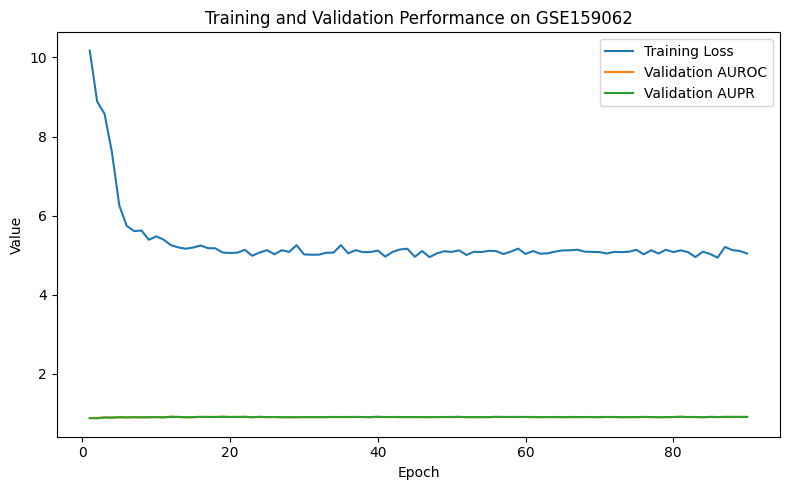

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

BASE = "/content/drive/MyDrive/MultiCausGRN_Pompe/Results/Pompe/POMPE_GSE159062_genes6116_seed8"
OUT = BASE + "/figures"
os.makedirs(OUT, exist_ok=True)

history = pd.read_csv(f"{BASE}/training_history.csv")

plt.figure(figsize=(8, 5))
plt.plot(history["epoch"], history["train_loss"], label="Training Loss")
plt.plot(history["epoch"], history["val_auc"], label="Validation AUROC")
plt.plot(history["epoch"], history["val_aupr"], label="Validation AUPR")

plt.xlabel("Epoch")
plt.ylabel("Value")
plt.title("Training and Validation Performance on GSE159062")
plt.legend()
plt.tight_layout()

plt.savefig(f"{OUT}/Figure_training_validation_curves_GSE159062.png", dpi=300)
plt.savefig(f"{OUT}/Figure_training_validation_curves_GSE159062.pdf")
plt.show()

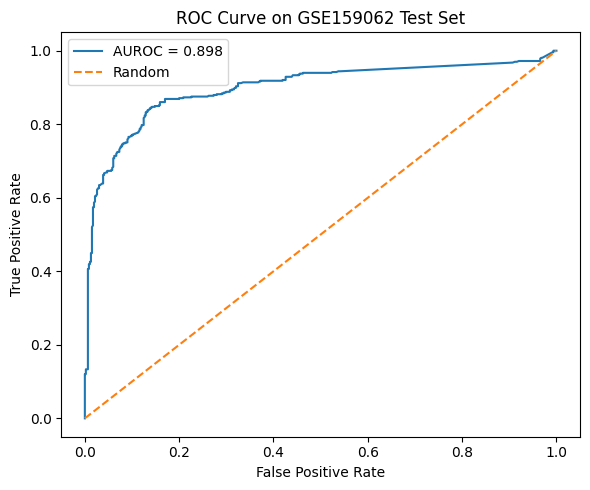

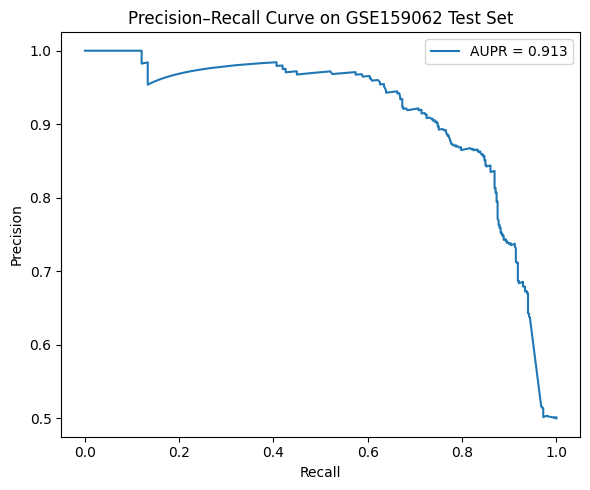

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import os

BASE = "/content/drive/MyDrive/MultiCausGRN_Pompe/Results/Pompe/POMPE_GSE159062_genes6116_seed8"
OUT = BASE + "/figures"
os.makedirs(OUT, exist_ok=True)

pred = pd.read_csv(f"{BASE}/test_final_predictions_named.csv")

y_true = pred["label"].astype(int)
y_score = pred["score"].astype(float)

# ROC
fpr, tpr, _ = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUROC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on GSE159062 Test Set")
plt.legend()
plt.tight_layout()

plt.savefig(f"{OUT}/Figure_ROC_GSE159062.png", dpi=300)
plt.savefig(f"{OUT}/Figure_ROC_GSE159062.pdf")
plt.show()

# Precision-Recall
precision, recall, _ = precision_recall_curve(y_true, y_score)
aupr = average_precision_score(y_true, y_score)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f"AUPR = {aupr:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve on GSE159062 Test Set")
plt.legend()
plt.tight_layout()

plt.savefig(f"{OUT}/Figure_PR_GSE159062.png", dpi=300)
plt.savefig(f"{OUT}/Figure_PR_GSE159062.pdf")
plt.show()

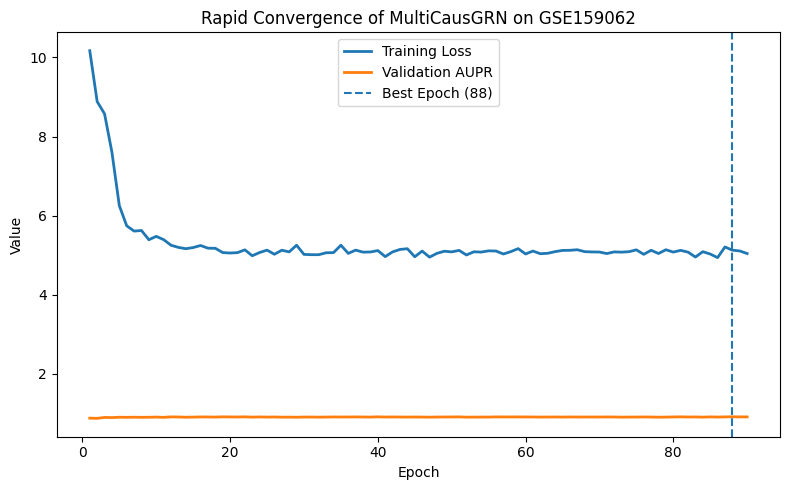

Best epoch: 88
Best validation AUPR: 0.9184


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

BASE = "/content/drive/MyDrive/MultiCausGRN_Pompe/Results/Pompe/POMPE_GSE159062_genes6116_seed8"

history = pd.read_csv(f"{BASE}/training_history.csv")

best_epoch = history.loc[
    history["val_aupr"].idxmax(),
    "epoch"
]

best_aupr = history["val_aupr"].max()

plt.figure(figsize=(8,5))

# training loss
plt.plot(
    history["epoch"],
    history["train_loss"],
    linewidth=2,
    label="Training Loss"
)

# validation AUPR
plt.plot(
    history["epoch"],
    history["val_aupr"],
    linewidth=2,
    label="Validation AUPR"
)

# best epoch
plt.axvline(
    best_epoch,
    linestyle="--",
    linewidth=1.5,
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Value")
plt.title("Rapid Convergence of MultiCausGRN on GSE159062")

plt.legend()
plt.tight_layout()

plt.savefig(
    f"{BASE}/figures/Figure_Convergence_GSE159062.png",
    dpi=300
)

plt.savefig(
    f"{BASE}/figures/Figure_Convergence_GSE159062.pdf"
)

plt.show()

print("Best epoch:", best_epoch)
print("Best validation AUPR:", round(best_aupr,4))

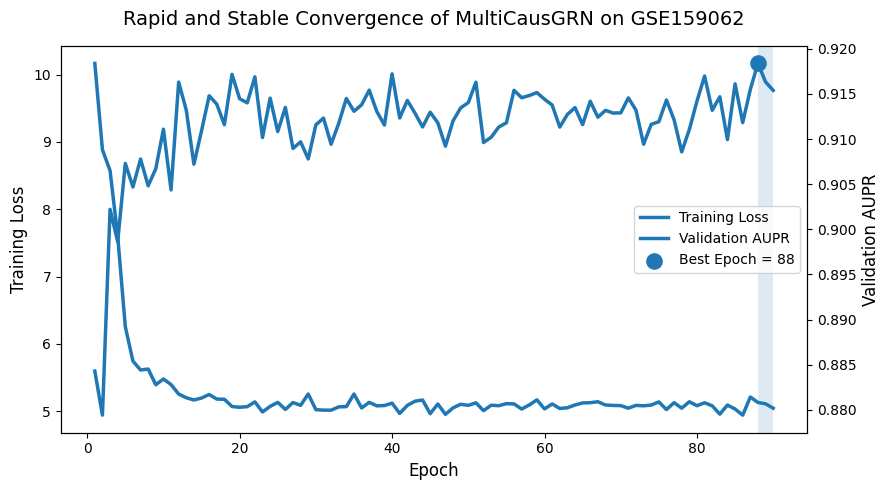

Best Epoch: 88
Best Validation AUPR: 0.9184


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# =========================
# Paths
# =========================
BASE = "/content/drive/MyDrive/MultiCausGRN_Pompe/Results/Pompe/POMPE_GSE159062_genes6116_seed8"
OUT = f"{BASE}/figures"

os.makedirs(OUT, exist_ok=True)

# =========================
# Load history
# =========================
history = pd.read_csv(f"{BASE}/training_history.csv")

# =========================
# Best epoch
# =========================
best_idx = history["val_aupr"].idxmax()

best_epoch = history.loc[best_idx, "epoch"]
best_aupr = history.loc[best_idx, "val_aupr"]

# =========================
# Create figure
# =========================
fig, ax1 = plt.subplots(figsize=(9,5))

# -------------------------
# LEFT axis = training loss
# -------------------------
ax1.plot(
    history["epoch"],
    history["train_loss"],
    linewidth=2.5,
    label="Training Loss"
)

ax1.set_xlabel("Epoch", fontsize=12)
ax1.set_ylabel("Training Loss", fontsize=12)

# -------------------------
# RIGHT axis = validation AUPR
# -------------------------
ax2 = ax1.twinx()

ax2.plot(
    history["epoch"],
    history["val_aupr"],
    linewidth=2.5,
    label="Validation AUPR"
)

ax2.set_ylabel("Validation AUPR", fontsize=12)

# =========================
# Best epoch marker
# =========================
ax2.scatter(
    best_epoch,
    best_aupr,
    s=120,
    zorder=5,
    label=f"Best Epoch = {best_epoch}"
)

# =========================
# Stabilization region
# =========================
ax1.axvspan(
    best_epoch,
    history["epoch"].max(),
    alpha=0.15
)

# =========================
# Combined legend
# =========================
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="center right",
    frameon=True
)

# =========================
# Title
# =========================
plt.title(
    "Rapid and Stable Convergence of MultiCausGRN on GSE159062",
    fontsize=14,
    pad=15
)

# =========================
# Layout
# =========================
plt.tight_layout()

# =========================
# Save
# =========================
plt.savefig(
    f"{OUT}/Figure_Convergence_GSE159062.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{OUT}/Figure_Convergence_GSE159062.pdf",
    bbox_inches="tight"
)

plt.show()

print("Best Epoch:", best_epoch)
print("Best Validation AUPR:", round(best_aupr,4))

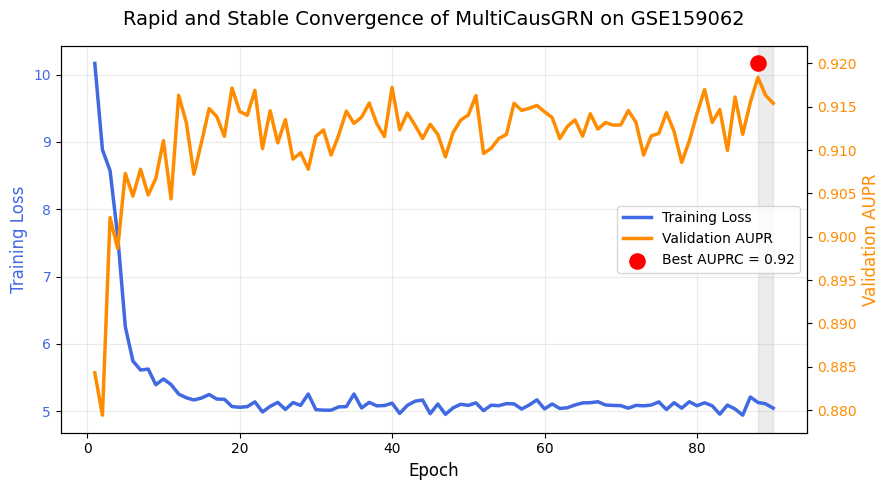

Best Epoch: 88
Best Validation AUPR: 0.92


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# =========================
# Paths
# =========================
BASE = "/content/drive/MyDrive/MultiCausGRN_Pompe/Results/Pompe/POMPE_GSE159062_genes6116_seed8"
OUT = f"{BASE}/figures"

os.makedirs(OUT, exist_ok=True)

# =========================
# Load history
# =========================
history = pd.read_csv(f"{BASE}/training_history.csv")

# =========================
# Best epoch
# =========================
best_idx = history["val_aupr"].idxmax()

best_epoch = history.loc[best_idx, "epoch"]
best_aupr = round(history.loc[best_idx, "val_aupr"],2)

# =========================
# Create figure
# =========================
fig, ax1 = plt.subplots(figsize=(9,5))

# -------------------------
# LEFT axis = training loss
# -------------------------
ax1.plot(
    history["epoch"],
    history["train_loss"],
    color="royalblue",
    linewidth=2.5,
    label="Training Loss"
)

ax1.set_xlabel("Epoch", fontsize=12)
ax1.set_ylabel(
    "Training Loss",
    fontsize=12,
    color="royalblue"
)

ax1.tick_params(axis='y', labelcolor="royalblue")

# -------------------------
# RIGHT axis = validation AUPR
# -------------------------
ax2 = ax1.twinx()

ax2.plot(
    history["epoch"],
    history["val_aupr"],
    color="darkorange",
    linewidth=2.5,
    label="Validation AUPR"
)

ax2.set_ylabel(
    "Validation AUPR",
    fontsize=12,
    color="darkorange"
)

ax2.tick_params(axis='y', labelcolor="darkorange")

# =========================
# Best epoch marker
# =========================
ax2.scatter(
    best_epoch,
    best_aupr,
    color="red",
    s=120,
    zorder=5,
    label=f"Best AUPRC = {best_aupr}"
)

# =========================
# Stabilization region
# =========================
ax1.axvspan(
    best_epoch,
    history["epoch"].max(),
    color="gray",
    alpha=0.15
)

# =========================
# Combined legend
# =========================
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="center right",
    frameon=True,
    fontsize=10
)

# =========================
# Title
# =========================
plt.title(
    "Rapid and Stable Convergence of MultiCausGRN on GSE159062",
    fontsize=14,
    pad=15
)

# =========================
# Grid
# =========================
ax1.grid(alpha=0.25)

# =========================
# Layout
# =========================
plt.tight_layout()

# =========================
# Save
# =========================
plt.savefig(
    f"{OUT}/Figure_Convergence_GSE159062_colored.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{OUT}/Figure_Convergence_GSE159062_colored.pdf",
    bbox_inches="tight"
)

plt.show()

print("Best Epoch:", best_epoch)
print("Best Validation AUPR:", round(best_aupr,4))

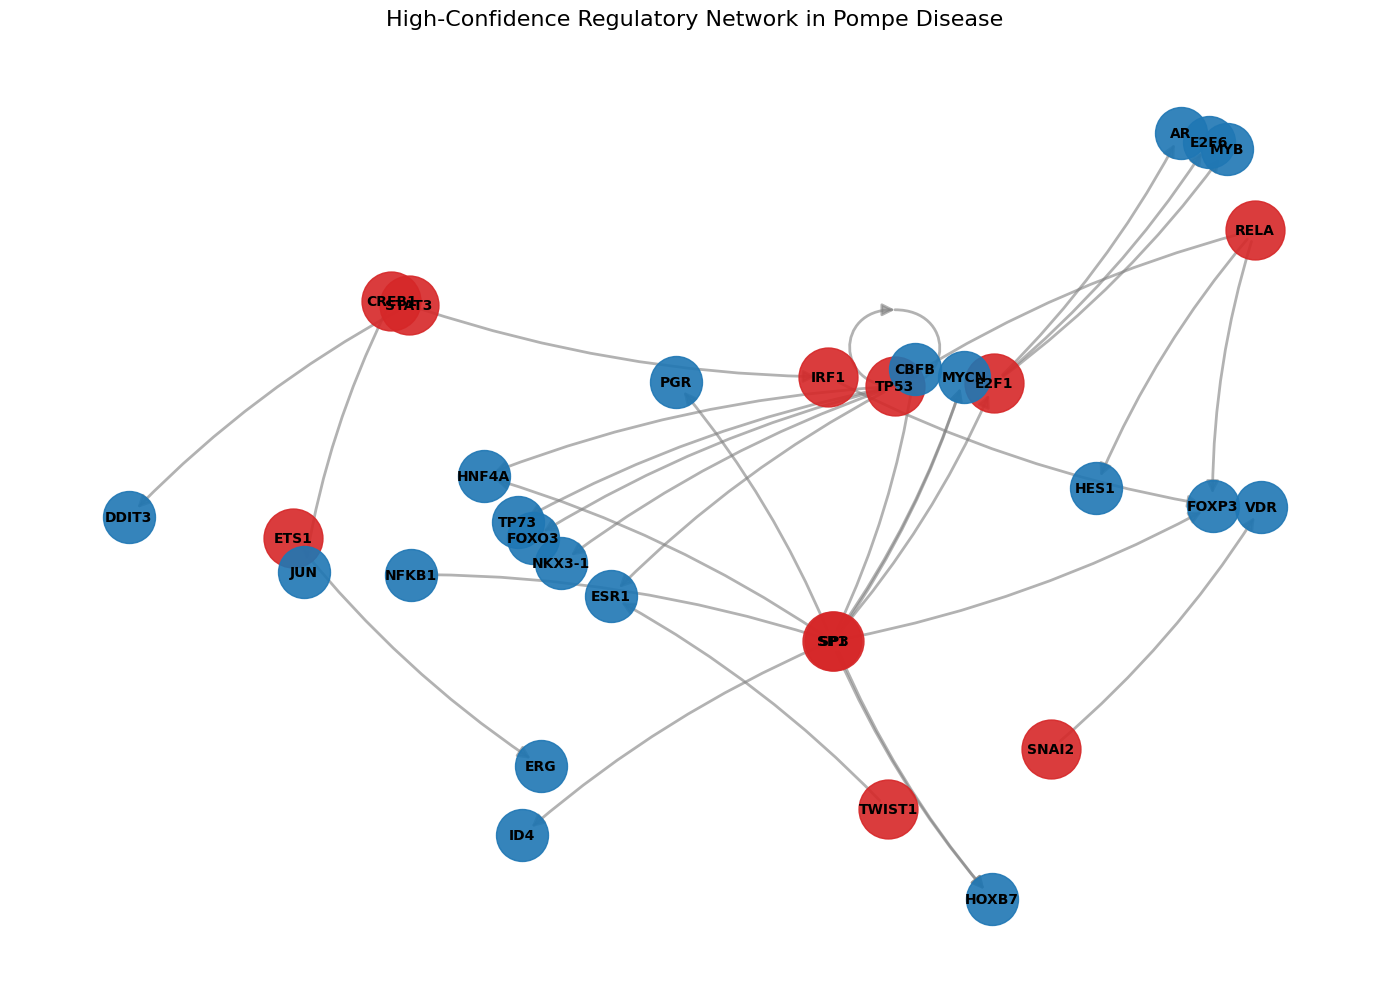

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import os

BASE = "/content/drive/MyDrive/MultiCausGRN_Pompe/Results/Pompe/POMPE_GSE159062_genes6116_seed8"

# =========================
# Load predictions
# =========================
pred = pd.read_csv(
    f"{BASE}/test_final_predictions_named.csv"
)

# top edges
top = pred.sort_values(
    "score",
    ascending=False
).head(30)

# =========================
# Build graph
# =========================
G = nx.DiGraph()

for _, row in top.iterrows():

    tf = row["TF"]
    tg = row["Target"]
    score = row["score"]

    G.add_edge(tf, tg, weight=score)

# =========================
# TF nodes
# =========================
tf_nodes = set(top["TF"])

# =========================
# Better layout
# =========================
pos = nx.kamada_kawai_layout(G)

# =========================
# Figure
# =========================
plt.figure(figsize=(14,10))

# -------------------------
# TF nodes
# -------------------------
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=list(tf_nodes),
    node_size=1800,
    node_color="#d62728",
    alpha=0.9
)

# -------------------------
# Target-only nodes
# -------------------------
target_only = [
    n for n in G.nodes()
    if n not in tf_nodes
]

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=target_only,
    node_size=1400,
    node_color="#1f77b4",
    alpha=0.9
)

# -------------------------
# Edges
# -------------------------
nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=18,
    width=2,
    alpha=0.6,
    edge_color="gray",
    connectionstyle="arc3,rad=0.08"
)

# -------------------------
# Labels
# -------------------------
nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_weight="bold"
)

# =========================
# Title
# =========================
plt.title(
    "High-Confidence Regulatory Network in Pompe Disease",
    fontsize=16,
    pad=20
)

plt.axis("off")

plt.tight_layout()

# =========================
# Save
# =========================
OUT = f"{BASE}/figures"

os.makedirs(OUT, exist_ok=True)

plt.savefig(
    f"{OUT}/Figure_Top_Regulatory_Network_Improved.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{OUT}/Figure_Top_Regulatory_Network_Improved.pdf",
    bbox_inches="tight"
)

plt.show()

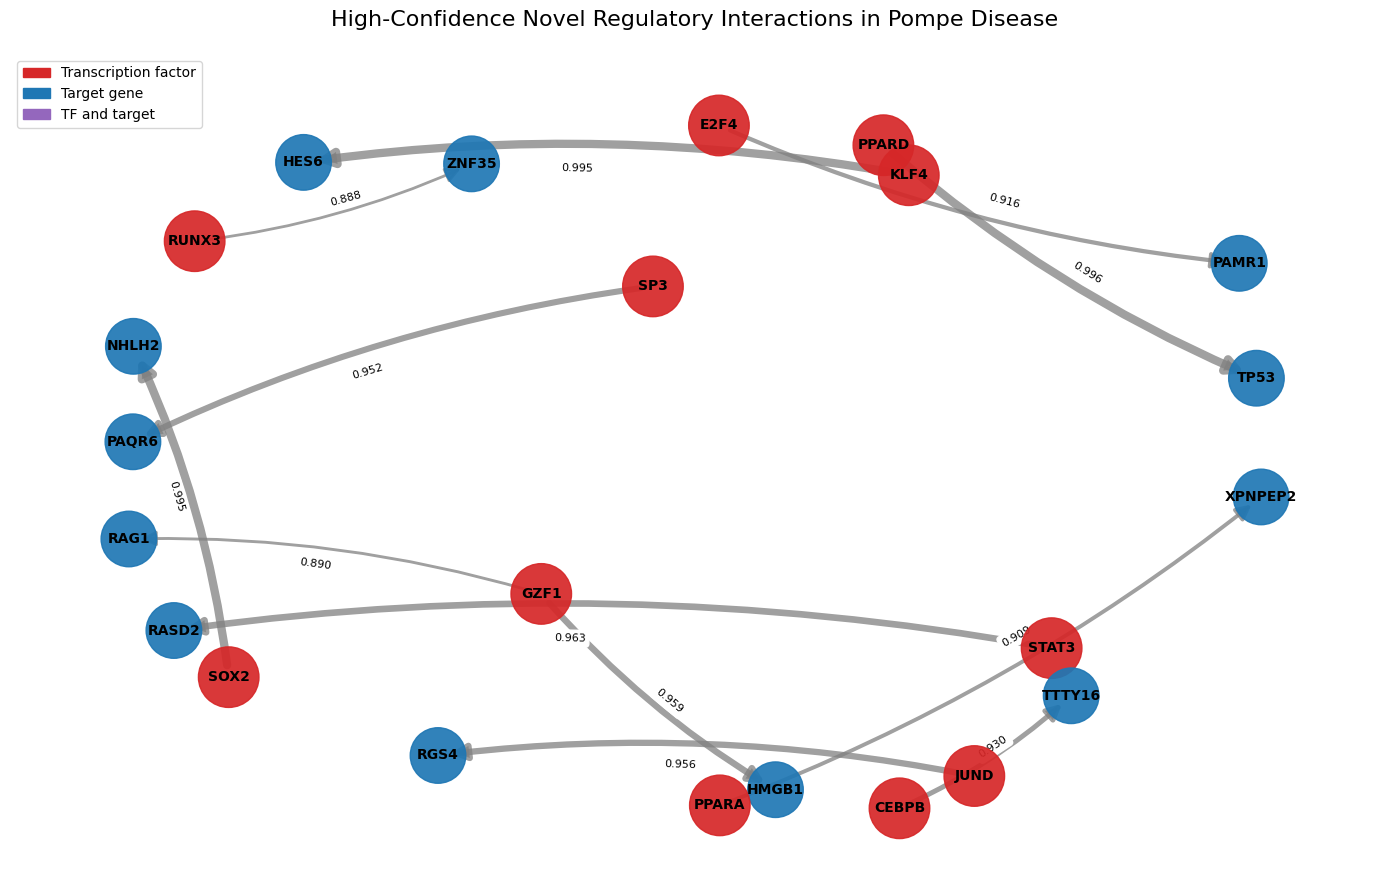

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import os

# =========================
# Paths
# =========================
BASE = "/content/drive/MyDrive/MultiCausGRN_Pompe/Results/Pompe/POMPE_GSE159062_genes6116_seed8"
OUT = f"{BASE}/figures"
os.makedirs(OUT, exist_ok=True)

# =========================
# Create novel edges table
# =========================
novel_edges = pd.DataFrame({
    "TF": [
        "PPARD", "SOX2", "KLF4", "STAT3", "GZF1", "JUND",
        "SP3", "CEBPB", "E2F4", "PPARA", "GZF1", "RUNX3"
    ],
    "Target": [
        "TP53", "NHLH2", "HES6", "RASD2", "HMGB1", "RGS4",
        "PAQR6", "TTTY16", "PAMR1", "XPNPEP2", "RAG1", "ZNF35"
    ],
    "Score": [
        0.995613, 0.994794, 0.994775, 0.962847, 0.958636, 0.956348,
        0.952488, 0.929962, 0.916028, 0.909470, 0.889903, 0.887722
    ]
})

novel_edges.to_csv(f"{OUT}/Novel_edges_top_candidates.csv", index=False)

# =========================
# Build directed graph
# =========================
G = nx.DiGraph()

for _, row in novel_edges.iterrows():
    G.add_edge(row["TF"], row["Target"], weight=row["Score"])

tf_nodes = set(novel_edges["TF"])
target_nodes = set(novel_edges["Target"])

# =========================
# Layout
# =========================
pos = nx.spring_layout(G, seed=42, k=1.2)

# =========================
# Node colors
# =========================
node_colors = []
node_sizes = []

for node in G.nodes():
    if node in tf_nodes and node in target_nodes:
        node_colors.append("#9467bd")  # both TF and target
        node_sizes.append(1900)
    elif node in tf_nodes:
        node_colors.append("#d62728")  # TF
        node_sizes.append(1900)
    else:
        node_colors.append("#1f77b4")  # target
        node_sizes.append(1600)

# =========================
# Edge widths by score
# =========================
scores = [G[u][v]["weight"] for u, v in G.edges()]
edge_widths = [2 + (s - min(scores)) / (max(scores) - min(scores)) * 4 for s in scores]

# =========================
# Draw figure
# =========================
plt.figure(figsize=(14, 9))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color=node_colors,
    node_size=node_sizes,
    alpha=0.92
)

nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=22,
    width=edge_widths,
    edge_color="gray",
    alpha=0.75,
    connectionstyle="arc3,rad=0.08"
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_weight="bold"
)

# Edge labels with scores
edge_labels = {
    (u, v): f"{G[u][v]['weight']:.3f}"
    for u, v in G.edges()
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=8,
    label_pos=0.55
)

# Legend
import matplotlib.patches as mpatches

tf_patch = mpatches.Patch(color="#d62728", label="Transcription factor")
target_patch = mpatches.Patch(color="#1f77b4", label="Target gene")
both_patch = mpatches.Patch(color="#9467bd", label="TF and target")

plt.legend(
    handles=[tf_patch, target_patch, both_patch],
    loc="upper left",
    frameon=True
)

plt.title(
    "High-Confidence Novel Regulatory Interactions in Pompe Disease",
    fontsize=16,
    pad=20
)

plt.axis("off")
plt.tight_layout()

plt.savefig(f"{OUT}/Figure_Novel_Regulatory_Network.png", dpi=600, bbox_inches="tight")
plt.savefig(f"{OUT}/Figure_Novel_Regulatory_Network.pdf", bbox_inches="tight")

plt.show()

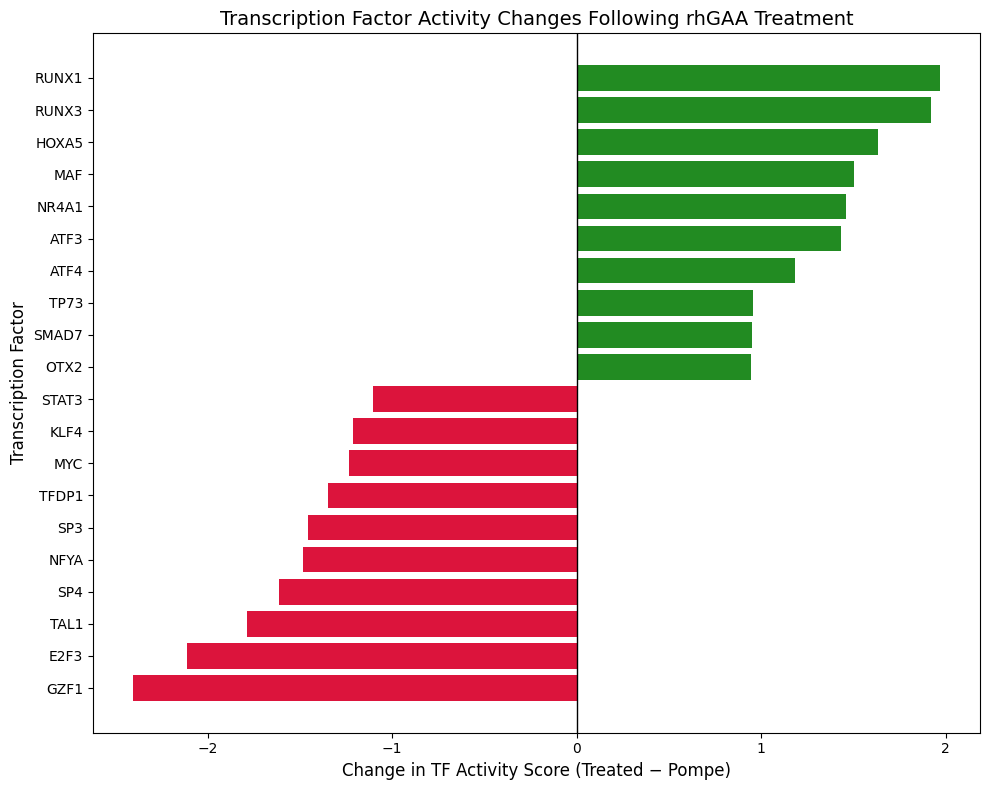

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# Top decreased TFs after treatment
# ==========================================
down = pd.DataFrame({
    "TF": ["GZF1","E2F3","TAL1","SP4","NFYA","SP3","TFDP1","MYC","KLF4","STAT3"],
    "change": [-2.401814,-2.109945,-1.787628,-1.613046,-1.483835,
               -1.454402,-1.349254,-1.235622,-1.213645,-1.101160]
})

# ==========================================
# Top increased TFs after treatment
# ==========================================
up = pd.DataFrame({
    "TF": ["RUNX1","RUNX3","HOXA5","MAF","NR4A1",
           "ATF3","ATF4","TP73","SMAD7","OTX2"],
    "change": [1.967261,1.918005,1.634476,1.505321,1.461891,
               1.434096,1.181650,0.958259,0.951578,0.945481]
})

# Merge and sort
plot_df = pd.concat([down, up], ignore_index=True)
plot_df = plot_df.sort_values("change")

# ==========================================
# Plot
# ==========================================
plt.figure(figsize=(10,8))

colors = ["crimson" if x < 0 else "forestgreen"
          for x in plot_df["change"]]

plt.barh(plot_df["TF"], plot_df["change"], color=colors)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Change in TF Activity Score (Treated − Pompe)", fontsize=12)
plt.ylabel("Transcription Factor", fontsize=12)
plt.title("Transcription Factor Activity Changes Following rhGAA Treatment",
          fontsize=14)

plt.tight_layout()

plt.savefig("Figure22_TF_Activity_Changes.png",
            dpi=600,
            bbox_inches="tight")

plt.savefig("Figure22_TF_Activity_Changes.pdf",
            bbox_inches="tight")

plt.show()

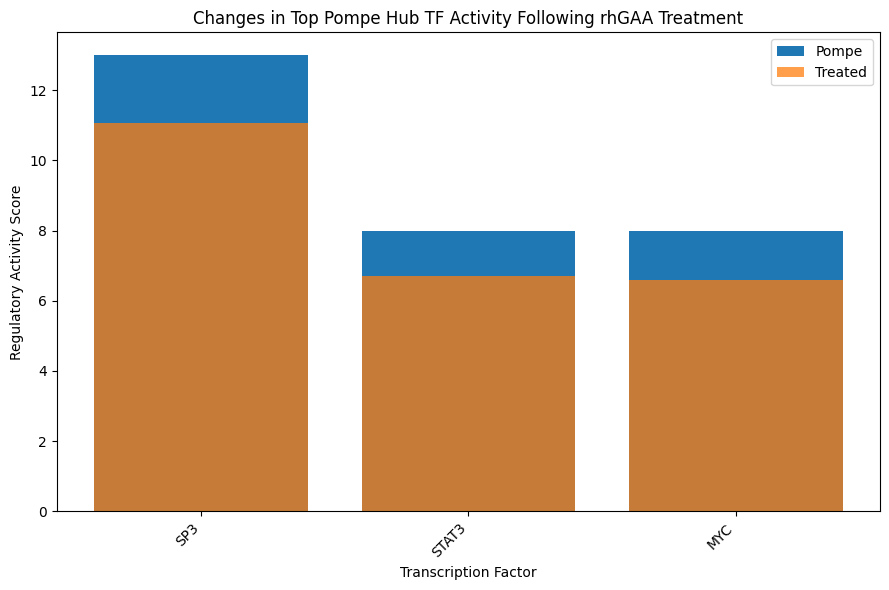

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Top Pompe hub TFs only
data = pd.DataFrame({
    "TF": ["SP1","NFKB1","RELA","TP53","E2F1","SP3","STAT3","MYC","ESR1","CREB1"],
    "pompe_score": [36,19,18,17,15,13,8,8,8,7],   # replace with exact values if you have them
    "treated_score": [None,None,None,None,None,11.065148,6.718023,6.579921,None,None]
})

# If exact treated scores are unavailable, use your actual merged dataframe instead:
# top_tfs = ["SP1","NFKB1","RELA","TP53","E2F1","SP3","STAT3","MYC","ESR1","CREB1"]
# data = merged[merged["TF"].isin(top_tfs)].copy()

data = data.dropna()
data["change"] = data["treated_score"] - data["pompe_score"]

plt.figure(figsize=(9,6))
plt.bar(data["TF"], data["pompe_score"], label="Pompe")
plt.bar(data["TF"], data["treated_score"], label="Treated", alpha=0.75)

plt.ylabel("Regulatory Activity Score")
plt.xlabel("Transcription Factor")
plt.title("Changes in Top Pompe Hub TF Activity Following rhGAA Treatment")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()

plt.savefig("Figure22_Top_Hub_TFs_rhGAA.png", dpi=600, bbox_inches="tight")
plt.savefig("Figure22_Top_Hub_TFs_rhGAA.pdf", bbox_inches="tight")
plt.show()